# Gaussian-RKHS single-switch experiment

This notebook reproduces the numerical experiment reported in Section VII of the manuscript.
No external data are required.


## 1. Online regression algorithms

The code below implements the three methods used in the experiment: static VAW,
VE-DVAW, and DS-FLH--VAW.

For a VAW learner started at $s$, the prediction is based on

$$
w_t^J\in\arg\min_{w\in\mathbb R^d}
\left\{
\mu\|w\|_2^2
+\sum_{r=s}^{t-1}(y_r-\langle w,x_r\rangle)^2
+\langle w,x_t\rangle^2
\right\},
$$

with raw prediction

$$
\widetilde y_t^J=\langle w_t^J,x_t\rangle.
$$

For DS-FLH, a learner born at $s$ is active on

$$
D_s=[s,e_s],
\qquad
e_s=s+2^{\nu_2(s)}-1,
$$

where $\nu_2(s)$ is the largest $k$ such that $2^k$ divides $s$.
The meta-prediction is

$$
\widehat h_t=\sum_{s\in\mathcal A_t}p_t^s h_t^s.
$$


In [1]:

from __future__ import annotations

import time
from typing import Any

import numpy as np
from numpy.typing import ArrayLike, NDArray


class FastVAW:
    """Standard VAW with Sherman--Morrison inverse updates."""

    def __init__(self, dimension: int, mu: float) -> None:
        if dimension <= 0:
            raise ValueError("dimension must be positive.")
        if not np.isfinite(mu) or mu <= 0:
            raise ValueError("mu must be a positive finite number.")
        self.dimension = int(dimension)
        self.mu = float(mu)
        self.reset()

    def reset(self) -> None:
        self.P: NDArray[np.float64] = (
            np.eye(self.dimension, dtype=np.float64) / self.mu
        )
        self.b: NDArray[np.float64] = np.zeros(
            self.dimension, dtype=np.float64
        )
        self.n_updates = 0

    def _validate_x(self, x: ArrayLike) -> NDArray[np.float64]:
        x_array = np.asarray(x, dtype=np.float64)
        if x_array.shape != (self.dimension,):
            raise ValueError(
                f"x must have shape ({self.dimension},), "
                f"but has shape {x_array.shape}."
            )
        if not np.all(np.isfinite(x_array)):
            raise ValueError("x must contain only finite values.")
        return x_array

    def predict(self, x: ArrayLike) -> float:
        x_array = self._validate_x(x)
        Px = self.P @ x_array
        denominator = 1.0 + float(x_array @ Px)
        if not np.isfinite(denominator) or denominator <= 0:
            raise FloatingPointError(
                "Nonpositive or nonfinite Sherman--Morrison denominator."
            )
        numerator = float(x_array @ (self.P @ self.b))
        return numerator / denominator

    def update(self, x: ArrayLike, y: float) -> None:
        x_array = self._validate_x(x)
        if not np.isfinite(y):
            raise ValueError("y must be finite.")

        Px = self.P @ x_array
        denominator = 1.0 + float(x_array @ Px)
        if not np.isfinite(denominator) or denominator <= 0:
            raise FloatingPointError(
                "Nonpositive or nonfinite Sherman--Morrison denominator."
            )

        self.P -= np.outer(Px, Px) / denominator
        self.P = 0.5 * (self.P + self.P.T)
        self.b += float(y) * x_array
        self.n_updates += 1


class VAWProtocol:
    """Common predict(x, hint), update(y) interface for VAW."""

    def __init__(self, dimension: int, regularization: float) -> None:
        self.learner = FastVAW(dimension, regularization)
        self._pending_x: NDArray[np.float64] | None = None
        self._prediction_pending = False

    def predict(self, x: ArrayLike, hint: float = 0.0) -> float:
        del hint
        if self._prediction_pending:
            raise RuntimeError(
                "update(y) must be called before the next prediction."
            )
        x_array = np.asarray(x, dtype=np.float64)
        prediction = self.learner.predict(x_array)
        self._pending_x = x_array.copy()
        self._prediction_pending = True
        return float(prediction)

    def update(self, y: float) -> None:
        if not self._prediction_pending:
            raise RuntimeError("predict(x) must be called before update(y).")
        assert self._pending_x is not None
        self.learner.update(self._pending_x, float(y))
        self._pending_x = None
        self._prediction_pending = False


class DVAW:
    """
    Discounted VAW.

    For gamma>0:
        Sigma_t = gamma Sigma_{t-1} + x_t x_t^T,
        w_t = Sigma_t^{-1}(gamma b_{t-1} + hint_t x_t),
        b_t = gamma b_{t-1} + y_t x_t.

    For gamma=0, the prediction is exactly hint_t.
    """

    def __init__(
        self,
        dimension: int,
        gamma: float,
        regularization: float,
    ) -> None:
        if dimension <= 0:
            raise ValueError("dimension must be positive.")
        if not np.isfinite(gamma) or not (0.0 <= gamma <= 1.0):
            raise ValueError("gamma must belong to [0, 1].")
        if not np.isfinite(regularization) or regularization <= 0:
            raise ValueError("regularization must be positive and finite.")

        self.dimension = int(dimension)
        self.gamma = float(gamma)
        self.regularization = float(regularization)
        self.reset()

    def reset(self) -> None:
        self.b = np.zeros(self.dimension, dtype=np.float64)
        self.P = (
            np.eye(self.dimension, dtype=np.float64)
            / self.regularization
            if self.gamma > 0
            else None
        )
        self.n_updates = 0
        self.last_w = np.zeros(self.dimension, dtype=np.float64)
        self._prediction_pending = False
        self._pending_x: NDArray[np.float64] | None = None
        self._pending_next_P: NDArray[np.float64] | None = None

    def _validate_x(self, x: ArrayLike) -> NDArray[np.float64]:
        x_array = np.asarray(x, dtype=np.float64)
        if x_array.shape != (self.dimension,):
            raise ValueError(
                f"x must have shape ({self.dimension},), "
                f"but has shape {x_array.shape}."
            )
        if not np.all(np.isfinite(x_array)):
            raise ValueError("x must contain only finite values.")
        return x_array

    def _compute_next_inverse(
        self, x: NDArray[np.float64]
    ) -> NDArray[np.float64]:
        assert self.P is not None
        Px = self.P @ x
        denominator = self.gamma + float(x @ Px)
        if not np.isfinite(denominator) or denominator <= 0:
            raise FloatingPointError(
                "Invalid discounted Sherman--Morrison denominator."
            )
        next_P = (
            self.P - np.outer(Px, Px) / denominator
        ) / self.gamma
        return 0.5 * (next_P + next_P.T)

    def predict(self, x: ArrayLike, hint: float = 0.0) -> float:
        if self._prediction_pending:
            raise RuntimeError(
                "update(y) must be called before the next prediction."
            )

        x_array = self._validate_x(x)
        if not np.isfinite(hint):
            raise ValueError("hint must be finite.")
        hint_value = float(hint)

        if self.gamma == 0:
            next_P = None
            prediction = hint_value
            self.last_w.fill(0.0)
        else:
            next_P = self._compute_next_inverse(x_array)
            rhs = self.gamma * self.b + hint_value * x_array
            self.last_w = next_P @ rhs
            prediction = float(x_array @ self.last_w)

        self._pending_x = x_array.copy()
        self._pending_next_P = next_P
        self._prediction_pending = True
        return float(prediction)

    def update(self, y: float) -> None:
        if not self._prediction_pending:
            raise RuntimeError(
                "predict(x, hint) must be called before update(y)."
            )
        if not np.isfinite(y):
            raise ValueError("y must be finite.")

        x_array = self._pending_x
        assert x_array is not None

        if self.gamma > 0:
            assert self._pending_next_P is not None
            self.P = self._pending_next_P
            self.b = self.gamma * self.b + float(y) * x_array

        self.n_updates += 1
        self._prediction_pending = False
        self._pending_x = None
        self._pending_next_P = None


def make_theoretical_gamma_grid(
    dimension: int,
    horizon: int,
    base: float = 2.0,
) -> tuple[np.ndarray, np.ndarray]:
    """
    eta_min=2d, eta_max=dT,
    eta_i=min(eta_min*base**i, eta_max),
    gamma_i=eta_i/(1+eta_i).
    """
    if dimension <= 0 or horizon <= 0:
        raise ValueError("dimension and horizon must be positive.")
    if not np.isfinite(base) or base <= 1:
        raise ValueError("base must be greater than 1.")

    eta_min = 2.0 * dimension
    eta_max = float(dimension * horizon)

    values: list[float] = []
    eta = eta_min
    while eta < eta_max:
        values.append(float(eta))
        eta *= base
    values.append(eta_max)

    unique_values: list[float] = []
    for value in values:
        if (
            not unique_values
            or abs(value - unique_values[-1])
            > 1e-12 * max(1.0, abs(value))
        ):
            unique_values.append(value)

    etas = np.asarray(unique_values, dtype=np.float64)
    gammas = etas / (1.0 + etas)
    return etas, gammas


class VEDVAW:
    """VAW ensemble of DVAW experts on the theoretical gamma grid."""

    def __init__(
        self,
        dimension: int,
        horizon: int,
        base_regularization: float,
        meta_regularization: float,
        grid_base: float = 2.0,
    ) -> None:
        self.dimension = int(dimension)
        self.horizon = int(horizon)

        self.etas, self.gammas = make_theoretical_gamma_grid(
            self.dimension, self.horizon, grid_base
        )

        self.experts = [
            DVAW(
                self.dimension,
                float(gamma),
                base_regularization,
            )
            for gamma in self.gammas
        ]

        self.meta_dimension = 1 + len(self.experts)
        self.meta = FastVAW(
            self.meta_dimension,
            meta_regularization,
        )

        self._prediction_pending = False
        self._pending_meta_features: NDArray[np.float64] | None = None

        self.last_expert_predictions: NDArray[np.float64] | None = None
        self.last_meta_features: NDArray[np.float64] | None = None
        self.last_prediction: float | None = None

    def predict(self, x: ArrayLike, hint: float = 0.0) -> float:
        if self._prediction_pending:
            raise RuntimeError(
                "update(y) must be called before the next prediction."
            )

        hint_value = float(hint)
        expert_predictions = np.asarray(
            [
                expert.predict(x, hint=hint_value)
                for expert in self.experts
            ],
            dtype=np.float64,
        )
        meta_features = np.concatenate(
            (np.asarray([hint_value]), expert_predictions)
        )
        prediction = self.meta.predict(meta_features)

        self.last_expert_predictions = expert_predictions.copy()
        self.last_meta_features = meta_features.copy()
        self.last_prediction = float(prediction)
        self._pending_meta_features = meta_features
        self._prediction_pending = True
        return float(prediction)

    def update(self, y: float) -> None:
        if not self._prediction_pending:
            raise RuntimeError(
                "predict(x, hint) must be called before update(y)."
            )

        for expert in self.experts:
            expert.update(float(y))

        assert self._pending_meta_features is not None
        self.meta.update(self._pending_meta_features, float(y))

        self._prediction_pending = False
        self._pending_meta_features = None


def two_adic_valuation(n: int) -> int:
    if n <= 0:
        raise ValueError("n must be positive.")
    k = 0
    while n % 2 == 0:
        n //= 2
        k += 1
    return k


def expert_end_time(start: int) -> int:
    return start + 2 ** two_adic_valuation(start) - 1


def active_expert_starts(t: int) -> list[int]:
    if t <= 0:
        raise ValueError("t must be positive.")
    return [
        start
        for start in range(1, t + 1)
        if t <= expert_end_time(start)
    ]


class DataStreamingAdaFLHVAW:
    """Anytime DS-FLH with clipped VAW base learners."""

    def __init__(
        self,
        dimension: int,
        initial_scale: float,
    ) -> None:
        if dimension <= 0:
            raise ValueError("dimension must be positive.")
        if not np.isfinite(initial_scale) or initial_scale <= 0:
            raise ValueError("initial_scale must be positive and finite.")

        self.dimension = int(dimension)
        self.initial_scale = float(initial_scale)
        self.reset()

    @staticmethod
    def beta(t: int) -> float:
        value = np.e + t
        return float(value * np.log(value) ** 2)

    @classmethod
    def rho(cls, t: int) -> float:
        return 1.0 / (cls.beta(t) + 1.0)

    def _expert_regularization(self, start: int) -> float:
        lifetime = 2 ** two_adic_valuation(start)
        return 1.0 / (self.dimension * lifetime)

    def _new_expert(self, start: int) -> FastVAW:
        return FastVAW(
            self.dimension,
            self._expert_regularization(start),
        )

    def reset(self) -> None:
        self.current_round = 1
        self.current_scale = self.initial_scale
        self._prediction_pending = False

        self.experts: dict[int, FastVAW] = {
            1: self._new_expert(1)
        }
        self.end_times: dict[int, int] = {1: expert_end_time(1)}
        self.weights: dict[int, float] = {1: 1.0}

        self.last_active_starts: list[int] = []
        self.last_raw_predictions: dict[int, float] = {}
        self.last_clipped_predictions: dict[int, float] = {}
        self.last_weights: dict[int, float] = {}
        self.last_prediction: float | None = None
        self.last_alpha: float | None = None

        self._pending_x: NDArray[np.float64] | None = None

    def _validate_x(self, x: ArrayLike) -> NDArray[np.float64]:
        x_array = np.asarray(x, dtype=np.float64)
        if x_array.shape != (self.dimension,):
            raise ValueError(
                f"x must have shape ({self.dimension},), "
                f"but has shape {x_array.shape}."
            )
        if not np.all(np.isfinite(x_array)):
            raise ValueError("x must contain only finite values.")
        return x_array

    def predict(self, x: ArrayLike) -> float:
        if self._prediction_pending:
            raise RuntimeError(
                "update(y) must be called before the next prediction."
            )

        x_array = self._validate_x(x)
        starts = sorted(self.experts)

        raw = {
            s: self.experts[s].predict(x_array)
            for s in starts
        }
        clipped = {
            s: float(
                np.clip(
                    raw[s],
                    -self.current_scale,
                    self.current_scale,
                )
            )
            for s in starts
        }
        prediction = float(
            sum(self.weights[s] * clipped[s] for s in starts)
        )

        self.last_active_starts = starts.copy()
        self.last_raw_predictions = raw.copy()
        self.last_clipped_predictions = clipped.copy()
        self.last_weights = self.weights.copy()
        self.last_prediction = prediction
        self._pending_x = x_array.copy()
        self._prediction_pending = True
        return prediction

    def update(self, y: float) -> None:
        if not self._prediction_pending:
            raise RuntimeError("predict(x) must be called before update(y).")
        if not np.isfinite(y):
            raise ValueError("y must be finite.")

        y_value = float(y)
        t = self.current_round
        starts = self.last_active_starts
        x_array = self._pending_x
        assert x_array is not None

        next_scale = max(self.current_scale, abs(y_value))
        alpha_t = 1.0 / (8.0 * next_scale**2)
        self.last_alpha = alpha_t

        losses = np.asarray(
            [
                (self.last_clipped_predictions[s] - y_value) ** 2
                for s in starts
            ],
            dtype=np.float64,
        )
        probabilities = np.asarray(
            [self.weights[s] for s in starts],
            dtype=np.float64,
        )

        log_q = np.log(probabilities) - alpha_t * losses
        log_q -= np.max(log_q)
        q_array = np.exp(log_q)
        q_array /= np.sum(q_array)
        q_weights = {
            s: float(q)
            for s, q in zip(starts, q_array)
        }

        for s in starts:
            self.experts[s].update(x_array, y_value)

        next_round = t + 1
        survivors = [
            s for s in starts
            if next_round <= self.end_times[s]
        ]

        next_experts = {
            s: self.experts[s]
            for s in survivors
        }
        next_end_times = {
            s: self.end_times[s]
            for s in survivors
        }

        next_experts[next_round] = self._new_expert(next_round)
        next_end_times[next_round] = expert_end_time(next_round)

        beta_t = self.beta(t)
        rho_t = self.rho(t)

        unnormalized = {
            s: q_weights[s]
            for s in survivors
        }
        unnormalized[next_round] = 1.0 / beta_t

        total = sum(unnormalized.values())
        active_count = len(next_experts)

        next_weights = {
            s: (
                (1.0 - rho_t) * unnormalized[s] / total
                + rho_t / active_count
            )
            for s in next_experts
        }

        self.experts = next_experts
        self.end_times = next_end_times
        self.weights = next_weights
        self.current_round = next_round
        self.current_scale = next_scale

        self._pending_x = None
        self._prediction_pending = False


class AdaFLHProtocol:
    """Common predict(x, hint), update(y) interface for DS-FLH--VAW."""

    def __init__(
        self,
        dimension: int,
        initial_scale: float,
    ) -> None:
        self.learner = DataStreamingAdaFLHVAW(
            dimension,
            initial_scale,
        )

    def predict(self, x: ArrayLike, hint: float = 0.0) -> float:
        del hint
        return float(self.learner.predict(x))

    def update(self, y: float) -> None:
        self.learner.update(float(y))


def build_honest_learners(
    dimension: int,
    horizon: int,
    initial_scale: float = 0.1,
    grid_base: float = 2.0,
) -> dict[str, Any]:
    """
    VAW: mu=1/(dT).
    DS-FLH--VAW: mu_s=1/(d|D_s|).
    VE-DVAW: lambda_base=10/T, lambda_meta=0.1.
    """
    vaw_mu = 1.0 / (dimension * horizon)

    return {
        "VAW": VAWProtocol(
            dimension,
            vaw_mu,
        ),
        "VE-DVAW": VEDVAW(
            dimension,
            horizon,
            base_regularization=10.0 / horizon,
            meta_regularization=0.1,
            grid_base=grid_base,
        ),
        "DS-FLH-VAW": AdaFLHProtocol(
            dimension,
            initial_scale,
        ),
    }


def run_online_algorithm(
    name: str,
    learner: Any,
    features: np.ndarray,
    outcomes: np.ndarray,
    comparator_losses: np.ndarray,
    hints: np.ndarray | None = None,
    changepoints: np.ndarray | None = None,
    recovery_window: int = 25,
) -> dict[str, Any]:
    features = np.asarray(features, dtype=np.float64)
    outcomes = np.asarray(outcomes, dtype=np.float64)
    comparator_losses = np.asarray(
        comparator_losses, dtype=np.float64
    )

    horizon = len(outcomes)

    if features.shape[0] != horizon:
        raise ValueError(
            "features and outcomes must have the same length."
        )
    if comparator_losses.shape != (horizon,):
        raise ValueError(
            "comparator_losses must have shape (T,)."
        )

    hints_array = (
        np.zeros(horizon)
        if hints is None
        else np.asarray(hints, dtype=np.float64)
    )
    if hints_array.shape != (horizon,):
        raise ValueError("hints must have shape (T,).")

    predictions = np.empty(horizon)

    start_time = time.perf_counter()
    for t in range(horizon):
        predictions[t] = learner.predict(
            features[t],
            hint=float(hints_array[t]),
        )
        learner.update(float(outcomes[t]))
    runtime = time.perf_counter() - start_time

    losses = (predictions - outcomes) ** 2
    regret_increments = losses - comparator_losses
    cumulative_regret = np.cumsum(regret_increments)

    post_change_excess = np.nan
    if changepoints is not None and len(changepoints) > 0:
        values = []
        for change in changepoints:
            start = int(change)
            end = min(start + recovery_window, horizon)
            values.append(np.mean(regret_increments[start:end]))
        post_change_excess = float(np.mean(values))

    return {
        "name": name,
        "predictions": predictions,
        "losses": losses,
        "regret_increments": regret_increments,
        "cumulative_regret": cumulative_regret,
        "cumulative_loss": float(losses.sum()),
        "final_regret": float(cumulative_regret[-1]),
        "post_change_excess": post_change_excess,
        "runtime": float(runtime),
    }


def run_three_methods(
    features: np.ndarray,
    outcomes: np.ndarray,
    comparator_losses: np.ndarray,
    initial_scale: float = 0.1,
    hints: np.ndarray | None = None,
    changepoints: np.ndarray | None = None,
    recovery_window: int = 25,
) -> dict[str, dict[str, Any]]:
    features = np.asarray(features, dtype=np.float64)
    if features.ndim != 2:
        raise ValueError("features must have shape (T, d).")

    horizon, dimension = features.shape
    learners = build_honest_learners(
        dimension,
        horizon,
        initial_scale,
    )

    return {
        name: run_online_algorithm(
            name,
            learner,
            features,
            outcomes,
            comparator_losses,
            hints,
            changepoints,
            recovery_window,
        )
        for name, learner in learners.items()
    }


def print_results_table(
    results: dict[str, dict[str, Any]],
) -> None:
    print(
        f"{'Algorithm':<18}"
        f"{'Loss':>14}"
        f"{'Regret':>14}"
        f"{'Post-change':>16}"
        f"{'Time, s':>12}"
    )
    print("-" * 74)

    for name, result in results.items():
        print(
            f"{name:<18}"
            f"{result['cumulative_loss']:>14.4f}"
            f"{result['final_regret']:>14.4f}"
            f"{result['post_change_excess']:>16.4f}"
            f"{result['runtime']:>12.4f}"
        )


In [2]:

import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t as student_t


## 2. Deterministic Gaussian features

For a multi-index $\alpha=(\alpha_1,\ldots,\alpha_p)$, write

$$
|\alpha|=\alpha_1+\cdots+\alpha_p,
\qquad
\alpha!=\alpha_1!\cdots\alpha_p!,
\qquad
x^\alpha=\prod_{i=1}^p x_i^{\alpha_i}.
$$

The Gaussian basis functions are

$$
g_\alpha(x)=
\frac{x^\alpha}{\sigma^{|\alpha|}\sqrt{\alpha!}}
\exp\left(-\frac{\|x\|_2^2}{2\sigma^2}\right),
$$

and

$$
k_\sigma(x,z)=
\sum_{\alpha\in\mathbb N_0^p}g_\alpha(x)g_\alpha(z).
$$

For truncation level $M$,

$$
V_M=\operatorname{span}\{g_\alpha:|\alpha|\le M\},
\qquad
m_M=\dim V_M=\binom{p+M}{M},
$$

with feature map

$$
\Psi_M(x)=\bigl(g_\alpha(x)\bigr)_{|\alpha|\le M}\in\mathbb R^{m_M}.
$$

In the experiment, $M=6$ and $p=2$, hence $m_M=28$. Also
$\|\Psi_M(x)\|_2\le1$.


In [4]:
import math
from collections.abc import Iterator


def weak_compositions(
    total: int,
    parts: int,
) -> Iterator[tuple[int, ...]]:
    if total < 0:
        raise ValueError("total must be nonnegative.")
    if parts <= 0:
        raise ValueError("parts must be positive.")

    if parts == 1:
        yield (total,)
        return

    for first in range(total + 1):
        for remainder in weak_compositions(
            total - first,
            parts - 1,
        ):
            yield (first,) + remainder


def multi_indices_up_to_degree(
    dimension: int,
    max_degree: int,
) -> NDArray[np.int64]:
    if dimension <= 0:
        raise ValueError("dimension must be positive.")
    if max_degree < 0:
        raise ValueError("max_degree must be nonnegative.")

    indices = [
        alpha
        for degree in range(max_degree + 1)
        for alpha in weak_compositions(degree, dimension)
    ]

    result = np.asarray(indices, dtype=np.int64)
    expected = math.comb(dimension + max_degree, max_degree)

    if result.shape != (expected, dimension):
        raise RuntimeError(
            "The generated multi-index set has an unexpected size."
        )

    return result


class GaussianTaylorFeatures:
    """
    Deterministic Gaussian features

        g_alpha(x)
        =
        x^alpha
        / (sigma^{|alpha|} sqrt(alpha!))
        * exp(-||x||^2 / (2 sigma^2))

    for all |alpha| <= M.
    """

    def __init__(
        self,
        input_dimension: int,
        max_degree: int,
        sigma: float,
    ) -> None:
        if input_dimension <= 0:
            raise ValueError("input_dimension must be positive.")
        if max_degree < 0:
            raise ValueError("max_degree must be nonnegative.")
        if not np.isfinite(sigma) or sigma <= 0:
            raise ValueError("sigma must be positive and finite.")

        self.input_dimension = int(input_dimension)
        self.max_degree = int(max_degree)
        self.sigma = float(sigma)

        self.multi_indices = multi_indices_up_to_degree(
            self.input_dimension,
            self.max_degree,
        )
        self.dimension = self.multi_indices.shape[0]
        self.degrees = self.multi_indices.sum(axis=1)

        log_alpha_factorials = np.asarray(
            [
                sum(
                    math.lgamma(int(a) + 1.0)
                    for a in alpha
                )
                for alpha in self.multi_indices
            ],
            dtype=np.float64,
        )

        log_coefficients = (
            -self.degrees * math.log(self.sigma)
            -0.5 * log_alpha_factorials
        )
        self.coefficients = np.exp(log_coefficients)

    def _validate_x(
        self,
        x: ArrayLike,
    ) -> NDArray[np.float64]:
        x_array = np.asarray(x, dtype=np.float64)

        if x_array.shape != (self.input_dimension,):
            raise ValueError(
                f"x must have shape ({self.input_dimension},), "
                f"but has shape {x_array.shape}."
            )
        if not np.all(np.isfinite(x_array)):
            raise ValueError("x must contain only finite values.")

        return x_array

    def transform_one(
        self,
        x: ArrayLike,
    ) -> NDArray[np.float64]:
        x_array = self._validate_x(x)

        monomials = np.prod(
            np.power(
                x_array[None, :],
                self.multi_indices,
            ),
            axis=1,
        )

        envelope = np.exp(
            -float(x_array @ x_array)
            / (2.0 * self.sigma**2)
        )

        return envelope * self.coefficients * monomials

    def transform(
        self,
        X: ArrayLike,
    ) -> NDArray[np.float64]:
        X_array = np.asarray(X, dtype=np.float64)

        if X_array.ndim == 1:
            return self.transform_one(X_array)

        if X_array.ndim != 2:
            raise ValueError(
                "X must be a one- or two-dimensional array."
            )
        if X_array.shape[1] != self.input_dimension:
            raise ValueError(
                f"X must have {self.input_dimension} columns, "
                f"but has shape {X_array.shape}."
            )
        if not np.all(np.isfinite(X_array)):
            raise ValueError("X must contain only finite values.")

        return np.vstack(
            [self.transform_one(x) for x in X_array]
        )

    def __call__(
        self,
        X: ArrayLike,
    ) -> NDArray[np.float64]:
        return self.transform(X)


## 3. Gaussian target and data generation

The Gaussian kernel is

$$
k_\sigma(x,z)=
\exp\left(-\frac{\|x-z\|_2^2}{2\sigma^2}\right).
$$

The target is

$$
h(x)=\sum_{j=1}^{q}v_j k_\sigma(x,c_j),
\qquad
\|h\|_{\mathcal H_\sigma}=1.
$$

The comparator sequence is

$$
f_t(x)=a_t h(x),
\qquad
a_t=
\begin{cases}
A,&t\le T/2,\\
-A,&t>T/2.
\end{cases}
$$

Thus $R_f=A$ and $P_T^{\mathcal H}=2A$. Observations are generated as

$$
y_t=f_t(x_t)+\varepsilon_t,
\qquad
\varepsilon_t\stackrel{\mathrm{i.i.d.}}{\sim}N(0,\tau^2).
$$

We use $p=2$, $r=1$, $\sigma=0.9$, $q=6$, $A=1$, and $\tau=0.1$.
The inputs $x_t$ and centers $c_j$ are sampled independently and uniformly from
$[-r/\sqrt p,r/\sqrt p]^p$.

For each repetition, one target and one input--noise sequence are generated.
The same sequence is used for all horizons in that repetition, with shorter
experiments obtained as prefixes of the longest one.


In [5]:

def gaussian_kernel_matrix(
    X: ArrayLike,
    Z: ArrayLike,
    sigma: float,
) -> NDArray[np.float64]:
    X_array = np.asarray(X, dtype=np.float64)
    Z_array = np.asarray(Z, dtype=np.float64)

    if X_array.ndim != 2 or Z_array.ndim != 2:
        raise ValueError("X and Z must be two-dimensional.")
    if X_array.shape[1] != Z_array.shape[1]:
        raise ValueError(
            "X and Z must have the same input dimension."
        )
    if not np.isfinite(sigma) or sigma <= 0:
        raise ValueError("sigma must be positive and finite.")

    X_squared = np.sum(X_array**2, axis=1)[:, None]
    Z_squared = np.sum(Z_array**2, axis=1)[None, :]

    distances_squared = (
        X_squared
        + Z_squared
        - 2.0 * X_array @ Z_array.T
    )
    distances_squared = np.maximum(
        distances_squared,
        0.0,
    )

    return np.exp(
        -distances_squared / (2.0 * sigma**2)
    )


def sample_inputs_in_ball_box(
    rng: np.random.Generator,
    n: int,
    dimension: int,
    radius: float,
) -> NDArray[np.float64]:
    """
    Sample uniformly from

        [-r/sqrt(p), r/sqrt(p)]^p,

    which is contained in the Euclidean ball B_r.
    """
    if n <= 0:
        raise ValueError("n must be positive.")
    if dimension <= 0:
        raise ValueError("dimension must be positive.")
    if not np.isfinite(radius) or radius <= 0:
        raise ValueError(
            "radius must be positive and finite."
        )

    half_width = radius / np.sqrt(dimension)

    return rng.uniform(
        -half_width,
        half_width,
        size=(n, dimension),
    )


def make_gaussian_target(
    seed: int,
    input_dimension: int = 2,
    radius: float = 1.0,
    sigma: float = 0.9,
    number_of_centers: int = 6,
    max_degree: int = 6,
) -> dict[str, Any]:
    """
    Construct

        h(x) = sum_j v_j k_sigma(x, c_j),

    normalized so that ||h||_H = 1, together with its deterministic
    Taylor-feature projection.
    """
    if number_of_centers <= 0:
        raise ValueError(
            "number_of_centers must be positive."
        )

    rng = np.random.default_rng(seed)

    centers = sample_inputs_in_ball_box(
        rng=rng,
        n=number_of_centers,
        dimension=input_dimension,
        radius=radius,
    )

    kernel_centers = gaussian_kernel_matrix(
        centers,
        centers,
        sigma=sigma,
    )

    raw_coefficients = rng.normal(
        size=number_of_centers
    )
    norm_squared = float(
        raw_coefficients
        @ kernel_centers
        @ raw_coefficients
    )

    if (
        not np.isfinite(norm_squared)
        or norm_squared <= 1e-14
    ):
        raise FloatingPointError(
            "Failed to generate a nonzero RKHS function."
        )

    coefficients = (
        raw_coefficients / np.sqrt(norm_squared)
    )

    np.testing.assert_allclose(
        float(
            coefficients
            @ kernel_centers
            @ coefficients
        ),
        1.0,
        rtol=1e-11,
        atol=1e-11,
    )

    feature_map = GaussianTaylorFeatures(
        input_dimension=input_dimension,
        max_degree=max_degree,
        sigma=sigma,
    )
    center_features = feature_map(centers)

    projected_coordinates = (
        center_features.T @ coefficients
    )

    return {
        "centers": centers,
        "coefficients": coefficients,
        "feature_map": feature_map,
        "projected_coordinates": (
            projected_coordinates
        ),
        "feature_dimension": (
            feature_map.dimension
        ),
        "parameters": {
            "p": input_dimension,
            "r": radius,
            "sigma": sigma,
            "q": number_of_centers,
            "M": max_degree,
            "seed": seed,
        },
    }


def make_master_gaussian_data(
    target: dict[str, Any],
    horizon: int,
    seed: int,
    noise_std: float = 0.1,
) -> dict[str, Any]:
    """
    Generate one master input/noise sequence. Smaller-horizon
    experiments use prefixes of this same sequence.
    """
    if horizon <= 0:
        raise ValueError("horizon must be positive.")
    if not np.isfinite(noise_std) or noise_std < 0:
        raise ValueError(
            "noise_std must be nonnegative and finite."
        )

    parameters = target["parameters"]
    rng = np.random.default_rng(seed)

    inputs = sample_inputs_in_ball_box(
        rng=rng,
        n=horizon,
        dimension=parameters["p"],
        radius=parameters["r"],
    )
    noise = noise_std * rng.normal(size=horizon)

    exact_values = (
        gaussian_kernel_matrix(
            inputs,
            target["centers"],
            sigma=parameters["sigma"],
        )
        @ target["coefficients"]
    )

    features = target["feature_map"](inputs)
    projected_values = (
        features
        @ target["projected_coordinates"]
    )

    projection_error = (
        projected_values - exact_values
    )

    return {
        "X": inputs,
        "Phi": features,
        "noise": noise,
        "h_exact": exact_values,
        "h_projected": projected_values,
        "projection_error": projection_error,
        "projection_rmse": float(
            np.sqrt(
                np.mean(projection_error**2)
            )
        ),
        "projection_max_error": float(
            np.max(np.abs(projection_error))
        ),
    }


def make_single_switch_stream(
    target: dict[str, Any],
    master: dict[str, Any],
    horizon: int,
    amplitude: float = 1.0,
) -> dict[str, Any]:
    """
    Use one abrupt switch at T/2:

        f_t = +A h,  t <= T/2,
        f_t = -A h,  t >  T/2.

    The RKHS path length is P_T^H = 2A.
    """
    if horizon <= 1:
        raise ValueError(
            "horizon must be greater than one."
        )
    if horizon > len(master["noise"]):
        raise ValueError(
            "horizon exceeds the master sequence."
        )
    if not np.isfinite(amplitude) or amplitude <= 0:
        raise ValueError(
            "amplitude must be positive and finite."
        )

    amplitudes = np.full(
        horizon,
        amplitude,
        dtype=np.float64,
    )
    amplitudes[horizon // 2 :] = -amplitude

    exact_signal = (
        amplitudes
        * master["h_exact"][:horizon]
    )
    projected_signal = (
        amplitudes
        * master["h_projected"][:horizon]
    )
    noise = master["noise"][:horizon]
    outcomes = exact_signal + noise

    exact_comparator_losses = noise**2
    projected_comparator_losses = (
        outcomes - projected_signal
    ) ** 2

    coordinates = target[
        "projected_coordinates"
    ]

    return {
        "Phi": master["Phi"][:horizon],
        "outcomes": outcomes,
        "exact_comparator_losses": (
            exact_comparator_losses
        ),
        "projected_comparator_losses": (
            projected_comparator_losses
        ),
        "exact_signal": exact_signal,
        "projected_signal": projected_signal,
        "amplitudes": amplitudes,
        "changepoints": np.array(
            [horizon // 2],
            dtype=np.int64,
        ),
        "P_H": 2.0 * amplitude,
        "P_l2": float(
            2.0
            * amplitude
            * np.linalg.norm(coordinates)
        ),
        "C_l1": float(
            2.0
            * amplitude
            * np.linalg.norm(
                coordinates,
                ord=1,
            )
        ),
        "B_inf": float(
            amplitude
            * np.linalg.norm(
                coordinates,
                ord=np.inf,
            )
        ),
        "signal_energy": float(
            np.sum(exact_signal**2)
        ),
        "projection_rmse": float(
            np.sqrt(
                np.mean(
                    (
                        master[
                            "projection_error"
                        ][:horizon]
                    ) ** 2
                )
            )
        ),
        "projection_max_error": float(
            np.max(
                np.abs(
                    master[
                        "projection_error"
                    ][:horizon]
                )
            )
        ),
    }


## 4. Learner parameters and experiment runner

All methods use the same finite-dimensional feature vectors $\Psi_M(x_t)$.
The regularization parameters are

$$
\mu_{\mathrm{VAW}}=\frac{1}{m_M T},
\qquad
\mu_s=\frac{1}{m_M|D_s|},
$$

and for VE-DVAW,

$$
\lambda_{\mathrm{base}}=\frac{1}{m_M},
\qquad
\lambda_{\mathrm{meta}}=1,
$$

with zero hint. No parameters are selected using the observed losses.

For a comparator sequence $f_{1:T}$, the reported dynamic regret is

$$
\operatorname{Reg}_T(f_{1:T})
=
\sum_{t=1}^T
\left[
(\widehat y_t-y_t)^2
-
(f_t(x_t)-y_t)^2
\right].
$$


In [6]:

def build_theoretical_learners(
    dimension: int,
    horizon: int,
    initial_scale: float = 0.1,
) -> dict[str, Any]:
    """
    Final parameterization used in this experiment:

        VAW:
            mu = 1 / (d T);

        DS-FLH--VAW:
            mu_s = 1 / (d |D_s|);

        VE-DVAW:
            lambda_base = 1 / d,
            lambda_meta = 1.
    """
    if dimension <= 0 or horizon <= 0:
        raise ValueError(
            "dimension and horizon must be positive."
        )

    vaw_mu = 1.0 / (dimension * horizon)

    return {
        "VAW": VAWProtocol(
            dimension=dimension,
            regularization=vaw_mu,
        ),
        "VE-DVAW": VEDVAW(
            dimension=dimension,
            horizon=horizon,
            base_regularization=(
                1.0 / dimension
            ),
            meta_regularization=1.0,
            grid_base=2.0,
        ),
        "DS-FLH-VAW": AdaFLHProtocol(
            dimension=dimension,
            initial_scale=initial_scale,
        ),
    }


def format_seconds(seconds: float) -> str:
    seconds = max(0.0, float(seconds))

    if seconds < 60:
        return f"{seconds:.1f}s"

    minutes, seconds = divmod(
        seconds,
        60,
    )

    if minutes < 60:
        return (
            f"{int(minutes)}m "
            f"{seconds:04.1f}s"
        )

    hours, minutes = divmod(
        minutes,
        60,
    )
    return (
        f"{int(hours)}h "
        f"{int(minutes)}m"
    )


def run_gaussian_single_switch_experiment(
    horizons: list[int],
    repetitions: int,
    base_seed: int = 31000,
    initial_scale: float = 0.1,
    amplitude: float = 1.0,
    noise_std: float = 0.1,
    target_parameters: dict[str, Any] | None = None,
    diagnostic_level: str = "algorithm",
) -> pd.DataFrame:
    """
    For each repetition:

    1. Generate one Gaussian-RKHS target h.
    2. Generate one master input/noise sequence up to max(horizons).
    3. Use prefixes for all horizons.
    4. Put the single switch exactly at T/2.

    Thus h is held fixed across horizons within a repetition.
    """
    if repetitions <= 0:
        raise ValueError(
            "repetitions must be positive."
        )
    if not horizons:
        raise ValueError(
            "horizons must be nonempty."
        )

    horizons = sorted(
        set(int(value) for value in horizons)
    )
    if any(value <= 1 for value in horizons):
        raise ValueError(
            "Every horizon must exceed one."
        )

    allowed_levels = {
        "none",
        "scenario",
        "algorithm",
    }
    if diagnostic_level not in allowed_levels:
        raise ValueError(
            f"diagnostic_level must be one of "
            f"{allowed_levels}."
        )

    if target_parameters is None:
        target_parameters = {}

    max_horizon = max(horizons)
    total_scenarios = (
        repetitions * len(horizons)
    )
    completed_scenarios = 0
    experiment_start = (
        time.perf_counter()
    )
    records: list[dict[str, Any]] = []

    for repetition in range(repetitions):
        target_seed = int(
            np.random.SeedSequence(
                [
                    int(base_seed),
                    int(repetition),
                    0,
                ]
            ).generate_state(1)[0]
        )
        data_seed = int(
            np.random.SeedSequence(
                [
                    int(base_seed),
                    int(repetition),
                    1,
                ]
            ).generate_state(1)[0]
        )

        target = make_gaussian_target(
            seed=target_seed,
            **target_parameters,
        )
        master = make_master_gaussian_data(
            target=target,
            horizon=max_horizon,
            seed=data_seed,
            noise_std=noise_std,
        )

        coordinates = target[
            "projected_coordinates"
        ]
        print(
            f"\nRepetition "
            f"{repetition + 1}/{repetitions}: "
            f"target_seed={target_seed}, "
            f"data_seed={data_seed}"
        )
        print(
            f"  feature dimension="
            f"{target['feature_dimension']}, "
            f"||w_M||_2="
            f"{np.linalg.norm(coordinates):.6f}, "
            f"||w_M||_1="
            f"{np.linalg.norm(coordinates, 1):.6f}"
        )
        print(
            f"  master projection RMSE="
            f"{master['projection_rmse']:.3e}, "
            f"max error="
            f"{master['projection_max_error']:.3e}"
        )

        for horizon in horizons:
            completed_scenarios += 1

            stream = make_single_switch_stream(
                target=target,
                master=master,
                horizon=horizon,
                amplitude=amplitude,
            )

            learners = (
                build_theoretical_learners(
                    dimension=target[
                        "feature_dimension"
                    ],
                    horizon=horizon,
                    initial_scale=(
                        initial_scale
                    ),
                )
            )

            if diagnostic_level != "none":
                print(
                    f"\nScenario "
                    f"{completed_scenarios}/"
                    f"{total_scenarios}: "
                    f"T={horizon}, K=1, "
                    f"rep={repetition + 1}/"
                    f"{repetitions}"
                )
                print(
                    f"  P_H={stream['P_H']:.6f}, "
                    f"P_l2={stream['P_l2']:.6f}, "
                    f"C_l1={stream['C_l1']:.6f}, "
                    f"projection RMSE="
                    f"{stream['projection_rmse']:.3e}"
                )

            results: dict[
                str,
                dict[str, Any],
            ] = {}

            for method_index, (
                method_name,
                learner,
            ) in enumerate(
                learners.items(),
                start=1,
            ):
                if (
                    diagnostic_level
                    == "algorithm"
                ):
                    print(
                        f"  [{method_index}/"
                        f"{len(learners)}] "
                        f"{method_name:<18}",
                        end="",
                        flush=True,
                    )

                result = run_online_algorithm(
                    name=method_name,
                    learner=learner,
                    features=stream["Phi"],
                    outcomes=stream[
                        "outcomes"
                    ],
                    comparator_losses=stream[
                        "exact_comparator_losses"
                    ],
                    hints=np.zeros(horizon),
                    changepoints=stream[
                        "changepoints"
                    ],
                    recovery_window=25,
                )

                projected_regret = float(
                    np.sum(
                        result["losses"]
                        - stream[
                            "projected_comparator_losses"
                        ]
                    )
                )
                results[method_name] = result

                records.append(
                    {
                        "T": horizon,
                        "K": 1,
                        "repetition": repetition,
                        "target_seed": target_seed,
                        "data_seed": data_seed,
                        "algorithm": method_name,
                        "final_regret": result[
                            "final_regret"
                        ],
                        "projected_regret": (
                            projected_regret
                        ),
                        "cumulative_loss": result[
                            "cumulative_loss"
                        ],
                        "post_change_excess": result[
                            "post_change_excess"
                        ],
                        "runtime": result[
                            "runtime"
                        ],
                        "feature_dimension": target[
                            "feature_dimension"
                        ],
                        "P_H": stream["P_H"],
                        "P_l2": stream["P_l2"],
                        "C_l1": stream["C_l1"],
                        "B_inf": stream["B_inf"],
                        "signal_energy": stream[
                            "signal_energy"
                        ],
                        "projection_rmse": stream[
                            "projection_rmse"
                        ],
                        "projection_max_error": (
                            stream[
                                "projection_max_error"
                            ]
                        ),
                    }
                )

                if (
                    diagnostic_level
                    == "algorithm"
                ):
                    print(
                        f" regret="
                        f"{result['final_regret']:>10.3f}"
                        f"  projected="
                        f"{projected_regret:>10.3f}"
                        f"  time="
                        f"{format_seconds(result['runtime'])}"
                    )

            difference = (
                results[
                    "DS-FLH-VAW"
                ]["final_regret"]
                - results[
                    "VE-DVAW"
                ]["final_regret"]
            )

            elapsed = (
                time.perf_counter()
                - experiment_start
            )
            mean_scenario_time = (
                elapsed
                / completed_scenarios
            )
            eta = (
                mean_scenario_time
                * (
                    total_scenarios
                    - completed_scenarios
                )
            )

            if diagnostic_level != "none":
                print(
                    f"  DS-FLH - VE = "
                    f"{difference:+.3f}; "
                    f"elapsed="
                    f"{format_seconds(elapsed)}, "
                    f"ETA="
                    f"{format_seconds(eta)}"
                )

    if diagnostic_level != "none":
        total_time = (
            time.perf_counter()
            - experiment_start
        )
        print(
            f"\nCompleted "
            f"{total_scenarios} scenarios "
            f"in "
            f"{format_seconds(total_time)}."
        )

    return pd.DataFrame.from_records(
        records
    )


## 5. Aggregation of results

For each horizon, dynamic regret is averaged over ten independent repetitions.
The final column is

$$
D_T=
\operatorname{Reg}_T^{\mathrm{DS\text{-}FLH}}
-
\operatorname{Reg}_T^{\mathrm{VE}}.
$$

Negative values of $D_T$ favor DS-FLH--VAW. The code also computes paired
$95\%$ confidence intervals for $D_T$.


In [7]:

def summarize_gaussian_experiment(
    records: pd.DataFrame,
) -> pd.DataFrame:
    means = (
        records
        .groupby(
            ["T", "algorithm"],
            as_index=False,
        )
        .agg(
            mean_regret=(
                "final_regret",
                "mean",
            ),
            mean_projected_regret=(
                "projected_regret",
                "mean",
            ),
            mean_runtime=(
                "runtime",
                "mean",
            ),
            repetitions=(
                "repetition",
                "nunique",
            ),
        )
        .pivot(
            index="T",
            columns="algorithm",
            values="mean_regret",
        )
        .reset_index()
    )

    paired = (
        records[
            records["algorithm"].isin(
                [
                    "VE-DVAW",
                    "DS-FLH-VAW",
                ]
            )
        ]
        .pivot_table(
            index=[
                "T",
                "repetition",
                "target_seed",
                "data_seed",
            ],
            columns="algorithm",
            values="final_regret",
        )
        .reset_index()
    )

    paired["DSFLH_minus_VE"] = (
        paired["DS-FLH-VAW"]
        - paired["VE-DVAW"]
    )

    difference = (
        paired
        .groupby("T")[
            "DSFLH_minus_VE"
        ]
        .agg(["mean", "std", "count"])
        .reset_index()
    )

    difference["se"] = (
        difference["std"]
        / np.sqrt(difference["count"])
    )
    difference["critical"] = (
        difference["count"].apply(
            lambda n: (
                student_t.ppf(
                    0.975,
                    n - 1,
                )
                if n > 1
                else np.nan
            )
        )
    )
    difference["ci95_low"] = (
        difference["mean"]
        - difference["critical"]
        * difference["se"]
    )
    difference["ci95_high"] = (
        difference["mean"]
        + difference["critical"]
        * difference["se"]
    )

    diagnostics = (
        records
        .groupby("T", as_index=False)
        .agg(
            feature_dimension=(
                "feature_dimension",
                "first",
            ),
            P_H=("P_H", "mean"),
            P_l2=("P_l2", "mean"),
            C_l1=("C_l1", "mean"),
            mean_signal_energy=(
                "signal_energy",
                "mean",
            ),
            mean_projection_rmse=(
                "projection_rmse",
                "mean",
            ),
            repetitions=(
                "repetition",
                "nunique",
            ),
        )
    )

    summary = (
        means
        .merge(
            difference[
                [
                    "T",
                    "mean",
                    "ci95_low",
                    "ci95_high",
                ]
            ],
            on="T",
        )
        .merge(
            diagnostics,
            on="T",
        )
        .rename(
            columns={
                "mean": (
                    "DSFLH_minus_VE"
                ),
            }
        )
    )

    return summary.sort_values(
        "T"
    ).reset_index(drop=True)


def plot_gaussian_results(
    summary: pd.DataFrame,
) -> None:
    plt.figure(figsize=(8, 4.5))

    for algorithm in [
        "VAW",
        "VE-DVAW",
        "DS-FLH-VAW",
    ]:
        plt.plot(
            summary["T"],
            summary[algorithm],
            marker="o",
            label=algorithm,
        )

    plt.xscale("log", base=2)
    plt.yscale("log")
    plt.xlabel("Horizon T")
    plt.ylabel("Mean dynamic regret")
    plt.title(
        "Gaussian-RKHS single-switch experiment"
    )
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()

    plt.figure(figsize=(8, 4.5))

    if summary[
        "ci95_low"
    ].notna().all():
        lower = (
            summary["DSFLH_minus_VE"]
            - summary["ci95_low"]
        )
        upper = (
            summary["ci95_high"]
            - summary["DSFLH_minus_VE"]
        )
        yerr = np.vstack([lower, upper])
    else:
        yerr = None

    plt.errorbar(
        summary["T"],
        summary["DSFLH_minus_VE"],
        yerr=yerr,
        marker="o",
        capsize=3,
    )
    plt.axhline(
        0.0,
        linestyle="--",
        linewidth=1.0,
    )
    plt.xscale("log", base=2)
    plt.xlabel("Horizon T")
    plt.ylabel(
        "Regret difference: DS-FLH - VE-DVAW"
    )
    plt.title(
        "Negative values favor DS-FLH-VAW"
    )
    plt.grid(alpha=0.25)
    plt.show()


## 6. Main experiment

The experiment uses

$$
T\in\{512,1024,2048,4096,8192,16384,32768,65536,131072\},
$$

with ten independent repetitions for each horizon.

The final cell produces the summary table and plots and writes

- `gaussian_single_switch_records_lifetime_mu.csv`;
- `gaussian_single_switch_summary_lifetime_mu.csv`.



Repetition 1/10: target_seed=544493839, data_seed=3075366002
  feature dimension=28, ||w_M||_2=1.000000, ||w_M||_1=1.225535
  master projection RMSE=7.096e-07, max error=7.295e-06

Scenario 1/90: T=512, K=1, rep=1/10
  P_H=2.000000, P_l2=2.000000, C_l1=2.451070, projection RMSE=6.585e-07
  DS-FLH - VE = -2.329; elapsed=3.1s, ETA=4m 34.6s

Scenario 2/90: T=1024, K=1, rep=1/10
  P_H=2.000000, P_l2=2.000000, C_l1=2.451070, projection RMSE=6.658e-07
  DS-FLH - VE = -2.171; elapsed=3.8s, ETA=2m 49.3s

Scenario 3/90: T=2048, K=1, rep=1/10
  P_H=2.000000, P_l2=2.000000, C_l1=2.451070, projection RMSE=6.942e-07
  DS-FLH - VE = -19.112; elapsed=5.6s, ETA=2m 42.1s

Scenario 4/90: T=4096, K=1, rep=1/10
  P_H=2.000000, P_l2=2.000000, C_l1=2.451070, projection RMSE=7.263e-07
  DS-FLH - VE = -48.377; elapsed=9.0s, ETA=3m 13.1s

Scenario 5/90: T=8192, K=1, rep=1/10
  P_H=2.000000, P_l2=2.000000, C_l1=2.451070, projection RMSE=6.996e-07
  DS-FLH - VE = -84.293; elapsed=16.3s, ETA=4m 37.1s

Scenario 6

,T,DS-FLH-VAW,VAW,VE-DVAW,DSFLH_minus_VE,ci95_low,ci95_high,feature_dimension,P_H,P_l2,C_l1,mean_signal_energy,mean_projection_rmse,repetitions
0,512,43.395645,194.998350,43.414360,-0.018715,-2.931081,2.893652,28,2.0,1.99999,4.267449,187.866838,0.000003,10
1,1024,55.453216,386.701919,56.829818,-1.376601,-2.921407,0.168204,28,2.0,1.99999,4.267449,376.034230,0.000003,10
2,2048,69.342452,764.005190,82.486536,-13.144084,-17.706441,-8.581727,28,2.0,1.99999,4.267449,753.075862,0.000003,10
3,4096,84.797250,1515.883976,113.392815,-28.595565,-35.943389,-21.247742,28,2.0,1.99999,4.267449,1500.599246,0.000003,10
4,8192,102.116461,3012.295328,153.450495,-51.334034,-67.693530,-34.974537,28,2.0,1.99999,4.267449,2997.818038,0.000003,10
5,16384,119.375282,6008.707938,199.454959,-80.079677,-105.367438,-54.791916,28,2.0,1.99999,4.267449,5992.534439,0.000003,10
6,32768,138.407024,11989.355756,255.905793,-117.498769,-153.196178,-81.801360,28,2.0,1.99999,4.267449,11981.581189,0.000003,10
7,65536,158.958254,23969.563546,328.983061,-170.024807,-220.877618,-119.171995,28,2.0,1.99999,4.267449,23944.023631,0.000003,10
8,131072,179.063557,47906.220254,421.490434,-242.426877,-309.870012,-174.983741,28,2.0,1.99999,4.267449,47884.408334,0.000003,10


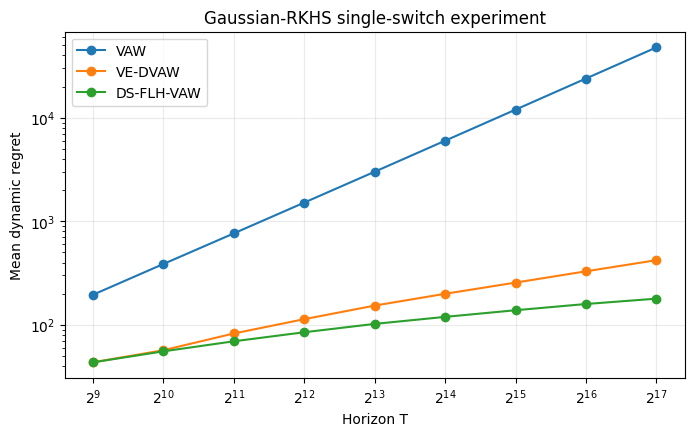

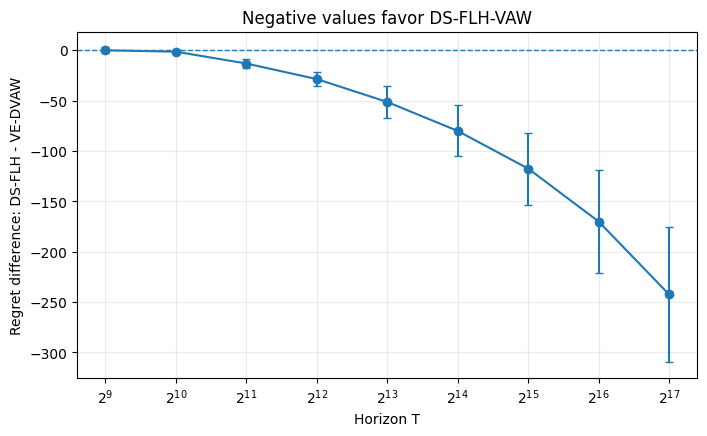

In [9]:
# Main experiment for Section VII ("An Experiment").
# The spatial setup is fixed; only the horizon changes.
# Ten independent repetitions are used, with nested prefixes within
# each repetition, exactly as in the previous Gaussian experiment.

HORIZONS = [
    512,
    1024,
    2048,
    4096,
    8192,
    16384,
    32768,
    65536,
    131072,
]
REPETITIONS = 10

TARGET_PARAMETERS = {
    "input_dimension": 2,
    "radius": 1.0,
    "sigma": 0.9,
    "number_of_centers": 6,
    "max_degree": 6,
}

gaussian_records = (
    run_gaussian_single_switch_experiment(
        horizons=HORIZONS,
        repetitions=REPETITIONS,
        base_seed=31000,
        initial_scale=0.1,
        amplitude=1.0,
        noise_std=0.1,
        target_parameters=TARGET_PARAMETERS,
        diagnostic_level="scenario",
    )
)

gaussian_summary = (
    summarize_gaussian_experiment(
        gaussian_records
    )
)

display(gaussian_summary)
plot_gaussian_results(gaussian_summary)

gaussian_records.to_csv(
    "gaussian_single_switch_records_lifetime_mu.csv",
    index=False,
)
gaussian_summary.to_csv(
    "gaussian_single_switch_summary_lifetime_mu.csv",
    index=False,
)
